# 5. Data Analysis

| | |
|---|---|
| **Aim** | Understand the model set before building a PD model |
| **Input** | `model_dataset.parquet` from Notebook 4 |
| **Output** | tables and charts in `reports/eda/` |

**Important for interpretation:**
- one loan appears in multiple snapshots, so the statistics describe snapshots, not individual loans;
- cohort composition affects the results. With multiple cohorts, the time-based chart does not describe the entire market.

In [1]:
import polars as pl

import config as C
import functions as F

pl.Config.set_tbl_rows(60)
pl.Config.set_tbl_cols(20)
pl.Config.set_fmt_str_lengths(70)
pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_tbl_hide_column_data_types(True)
C.REPORT_DIR.mkdir(parents=True, exist_ok=True)

import matplotlib.pyplot as plt

data = pl.scan_parquet(C.MODEL_FILE)
EDA_DIR = C.REPORT_DIR / "eda"
EDA_DIR.mkdir(parents=True, exist_ok=True)

## 1. Basic Info

In [2]:
overview = data.select(
    snapshots=pl.len(), loans=pl.col("loan_id").n_unique(), cohorts=pl.col("cohort").n_unique(),
    first_snapshot=pl.col("snapshot_date").min(), last_snapshot=pl.col("snapshot_date").max(),
    target_1=pl.col("target_12m").sum(), target_rate_pct=(pl.col("target_12m").mean() * 100).round(2),
    prepaid_rate_pct=(pl.col("prepaid_12m").mean() * 100).round(2),
).collect()
overview.write_csv(EDA_DIR / "overview.csv")
overview

snapshots,loans,cohorts,first_snapshot,last_snapshot,target_1,target_rate_pct,prepaid_rate_pct
204624,14998,2,2007-03-01,2025-06-01,5500,2.69,22.09


## 2. Numerical variables

In [3]:
numeric = F.numeric_summary(data)
numeric.write_csv(EDA_DIR / "numeric_stats.csv")
numeric

variable,missing_pct,mean,std,min,p01,p25,median,p75,p99,max
"""fico""",0.15,723.74,56.1,480.0,590.0,683.0,728.0,771.0,814.0,824.0
"""ltv_orig""",0.0,74.87,16.62,8.0,24.0,68.0,80.0,85.0,97.0,97.0
"""cltv_orig""",0.0,76.11,17.06,8.0,25.0,68.0,80.0,90.0,102.0,105.0
"""dti""",1.7,37.91,10.98,0.0,12.0,30.0,39.0,46.0,62.0,64.0
"""rate_orig""",0.0,5.72,0.72,3.75,4.25,5.0,5.88,6.25,7.25,8.25
"""loan_amount_k""",0.0,202.64,110.26,13.0,41.0,120.0,181.0,264.0,525.0,1313.0
"""mi_pct""",0.0,6.64,11.37,0.0,0.0,0.0,0.0,12.0,35.0,40.0
"""n_borrowers""",0.02,1.48,0.52,1.0,1.0,1.0,1.0,2.0,2.0,4.0
"""n_units""",0.0,1.04,0.25,1.0,1.0,1.0,1.0,1.0,2.0,4.0
"""months_delinquent""",0.0,0.09,0.73,0.0,0.0,0.0,0.0,0.0,2.0,28.0


## 3. Categorical variables

In [4]:
categories = F.category_summary(data)
categories.write_csv(EDA_DIR / "category_stats.csv")
categories

variable,value,snapshots,share_pct,target_rate_pct
"""purpose""","""P""",104125,50.89,1.73
"""purpose""","""C""",69757,34.09,3.8
"""purpose""","""R""",30742,15.02,3.38
"""occupancy""","""P""",176226,86.12,2.8
"""occupancy""","""I""",18559,9.07,2.11
"""occupancy""","""S""",9839,4.81,1.68
"""property_type""","""SF""",139500,68.17,2.91
"""property_type""","""PU""",40261,19.68,2.23
"""property_type""","""CO""",20550,10.04,2.32
"""property_type""","""MH""",2994,1.46,1.7


## 4. Target in time


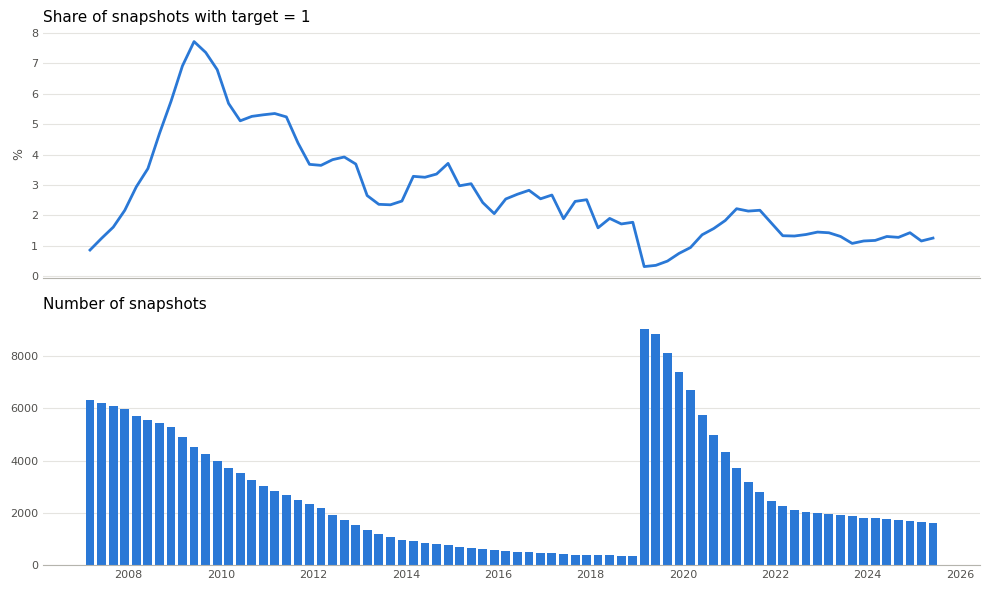

In [5]:
figure, table = F.plot_target_over_time(data)
figure.savefig(EDA_DIR / "target_over_time.png", dpi=150)
table.write_csv(EDA_DIR / "target_by_snapshot.csv")
plt.show()

## 5. Risk in different intervals

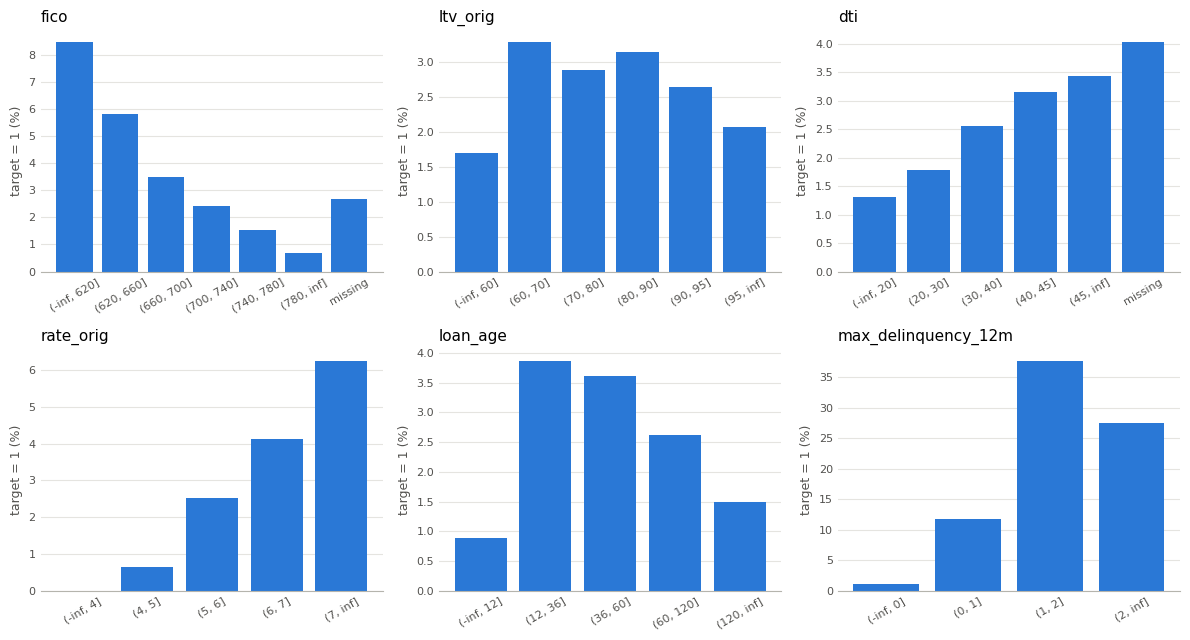

In [6]:
figure = F.plot_target_by_bins(data)
figure.savefig(EDA_DIR / "target_by_bins.png", dpi=150)
plt.show()

## 6. Correlation

In [7]:
sample, with_target = F.correlations(data)
with_target.write_csv(EDA_DIR / "correlations.csv")
with_target

variable,correlation_with_target
"""months_delinquent""",0.405
"""max_delinquency_12m""",0.316
"""n_late_months_12m""",0.316
"""rate_orig""",0.096
"""loan_age""",0.048
"""dti""",0.044
"""balance_k""",0.02
"""loan_amount_k""",0.016
"""cltv_orig""",0.012
"""paid_share""",0.012


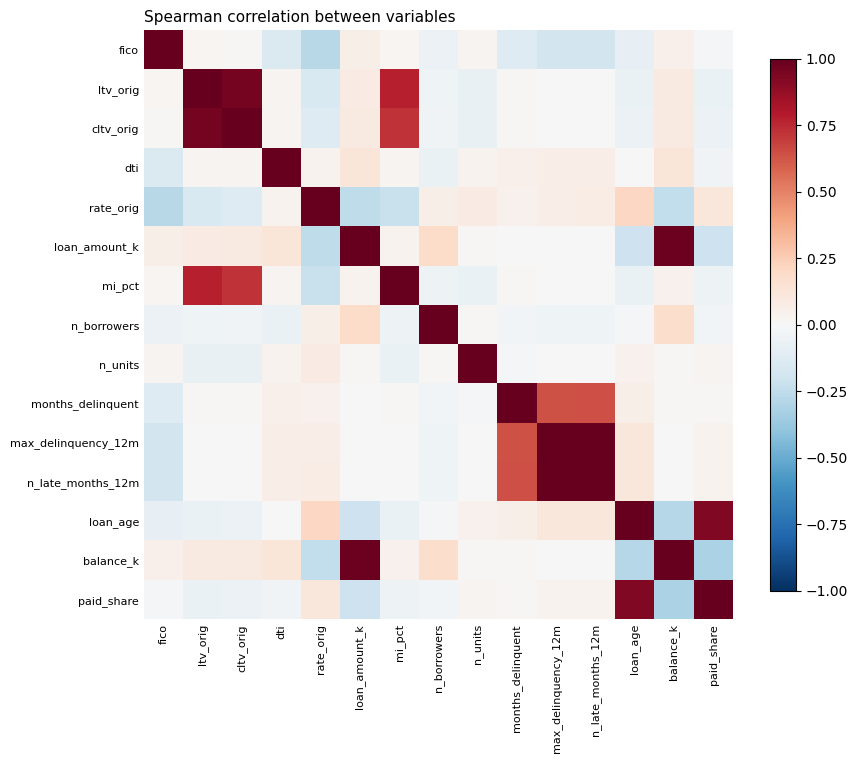

In [8]:
figure = F.plot_correlation_matrix(sample)
figure.savefig(EDA_DIR / "correlation_matrix.png", dpi=150)
plt.show()